In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Pepare Circulating Supply Data

In [21]:
data = pd.read_csv("../../../data/votable_supply-dhruvi/data/pr_raw_data.csv")

In [22]:
data['Date'] = pd.to_datetime(data['Date'], dayfirst=True)

# Step 1: Get the circulating supply as of 30th November 2024
current_data = data[data["Date"] == "2024-11-30"]
current_circulating_supply = current_data["Circulating Supply"].iloc[0]  # Extract the value

# Step 2: Calculate the remaining circulating supply for Dec 2024 - Apr 2025
forecasted_circulating_supply_2024_2025 = 1_695_895_615
remaining_circulating_supply_2024_2025 = forecasted_circulating_supply_2024_2025 - current_circulating_supply

# Distribute the remaining supply across Dec 2024 - Apr 2025
months_2024_2025 = pd.date_range(start="2024-12-01", end="2025-04-30", freq="MS")
monthly_increment_2024_2025 = remaining_circulating_supply_2024_2025 / len(months_2024_2025)

# Create daily data for Dec 2024 - Apr 2025
future_data_2024_2025 = []
monthly_supply = current_circulating_supply

for month_start in months_2024_2025:
    monthly_supply += monthly_increment_2024_2025
    daily_dates = pd.date_range(start=month_start, end=month_start + pd.offsets.MonthEnd(0), freq="D")
    for day in daily_dates:
        future_data_2024_2025.append({
            "Date": day,
            "Circulating Supply": monthly_supply
        })

future_data_2024_2025 = pd.DataFrame(future_data_2024_2025)
future_data_2024_2025["Votable Supply"] = future_data_2024_2025["Circulating Supply"] * 0.09


In [23]:
# Step 1: Get the circulating supply as of 30th April 2025
april_2025_data = future_data_2024_2025[future_data_2024_2025["Date"] == "2025-04-30"]
circulating_supply_april_2025 = april_2025_data["Circulating Supply"].iloc[0]

# Step 2: Forecasted CS for May 2025 - April 2026
forecasted_circulating_supply_2025_2026 = 2_458_161_470 
remaining_circulating_supply_2025_2026 = (
    forecasted_circulating_supply_2025_2026 - circulating_supply_april_2025
)

# Distribute the remaining supply across 12 months (May 2025 - April 2026)
months_2025_2026 = pd.date_range(start="2025-05-01", end="2026-04-30", freq="MS")
monthly_increment_2025_2026 = remaining_circulating_supply_2025_2026 / len(months_2025_2026)

# Create daily data for May 2025 - Dec 2025
future_data_2025 = []
monthly_supply = circulating_supply_april_2025

for month_start in months_2025_2026[:8]:  # May 2025 - Dec 2025
    monthly_supply += monthly_increment_2025_2026
    daily_dates = pd.date_range(start=month_start, end=month_start + pd.offsets.MonthEnd(0), freq="D")
    for day in daily_dates:
        future_data_2025.append({
            "Date": day,
            "Circulating Supply": monthly_supply
        })

# Step 3: Combine with previous data
future_data_2025 = pd.DataFrame(future_data_2025)
future_data_2025["Votable Supply"] = future_data_2025["Circulating Supply"] * 0.09


In [24]:
# Combine all data (2024, 2025, 2026)
combined_data = pd.concat([data, future_data_2024_2025, future_data_2025], ignore_index=True)

In [25]:
complete_data = pd.concat([future_data_2024_2025, future_data_2025], ignore_index=True)
complete_data.to_csv("../../../data/votable_supply-dhruvi/data/vs_cs_predicted_data.csv", index=False)

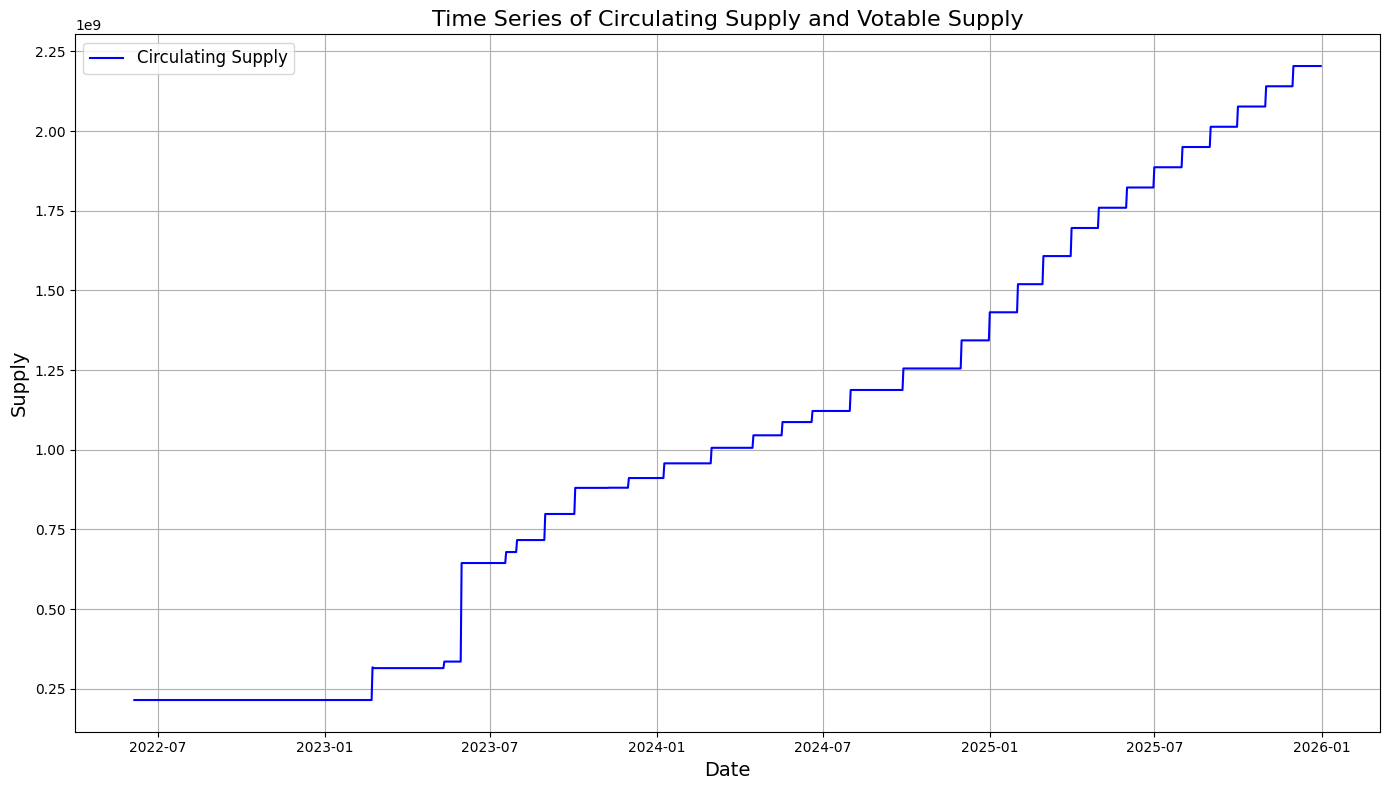

In [26]:
# Ensure 'Date' is in datetime format
combined_data["Date"] = pd.to_datetime(combined_data["Date"])

# Plotting
plt.figure(figsize=(14, 8))

# Plot Circulating Supply
plt.plot(combined_data["Date"], combined_data["Circulating Supply"], label="Circulating Supply", color="blue")

# Adding titles and labels
plt.title("Time Series of Circulating Supply and Votable Supply", fontsize=16)
plt.xlabel("Date", fontsize=14)
plt.ylabel("Supply", fontsize=14)
plt.legend(fontsize=12)
plt.grid(True)

# Show plot
plt.tight_layout()
plt.show()


### Combine all the predicted data

In [27]:
vs_cs_data = pd.read_csv("../../../data/votable_supply-dhruvi/data/vs_cs_predicted_data.csv")

In [28]:
vs_cs_data['Date'] = pd.to_datetime(vs_cs_data['Date'])

In [29]:
op_price_data = pd.read_csv("../../../data/votable_supply-dhruvi/data/op_price_predicted_data.csv")
avpi_data = pd.read_csv("../../../data/votable_supply-dhruvi/data/avpi_predicted_data.csv")
pr_data = pd.read_csv("../../../data/votable_supply-dhruvi/data/pr_predicted_data.csv")
lar_data = pd.read_csv("../../../data/votable_supply-dhruvi/data/lar_predicted_data.csv")
psi_data = pd.read_csv("../../../data/votable_supply-dhruvi/data/psi_predicted_data.csv")
vpi_data = pd.read_csv("../../../data/votable_supply-dhruvi/data/vpi_predicted_data.csv")

In [30]:
op_price_data['Date'] = pd.to_datetime(op_price_data['Date'], dayfirst=True)
avpi_data['Date'] = pd.to_datetime(avpi_data['Date'], dayfirst=True)
pr_data['Date'] = pd.to_datetime(pr_data['Date'], dayfirst=True)
lar_data['Date'] = pd.to_datetime(lar_data['Date'], dayfirst=True)
psi_data['Date'] = pd.to_datetime(psi_data['Date'], dayfirst=True)
vpi_data['Date'] = pd.to_datetime(vpi_data['Date'], dayfirst=True)

In [31]:
# Merge datasets on the 'Date' column
merged_data = pd.merge(op_price_data, avpi_data, on="Date", how="inner")
merged_data = pd.merge(merged_data, pr_data, on="Date", how="inner")
merged_data = pd.merge(merged_data, lar_data, on="Date", how="inner")
merged_data = pd.merge(merged_data, psi_data, on="Date", how="inner")
merged_data = pd.merge(merged_data, vpi_data, on="Date", how="inner")
merged_data = pd.merge(merged_data, vs_cs_data, on="Date", how="inner")

In [32]:
merged_data['OP_Price'] = round(merged_data['OP_Price'], 6)
merged_data['AVPI'] = round(merged_data['AVPI'], 6)
merged_data['PR'] = round(merged_data['PR'], 6)
merged_data['LAR'] = round(merged_data['LAR'], 6)
merged_data['PSI'] = round(merged_data['PSI'], 6)
merged_data['VPI'] = round(merged_data['VPI'], 6)
merged_data['Votable Supply'] = round(merged_data['Votable Supply'], 2)
merged_data['Circulating Supply'] = round(merged_data['Circulating Supply'], 2)

### Scale the parameters

In [33]:
# Sigmoid scaling of OP_Price
k = 1.5  
x0 = merged_data['OP_Price'].mean() 
merged_data['OP_Price_Scaled'] = 1 / (1 + np.exp(-k * (merged_data['OP_Price'] - x0)))

In [34]:
# Sigmoid scaling of Liquidity Activity Ratio (LAR)
k = 5  
x0 = merged_data['LAR'].mean() 
merged_data['LAR_Scaled'] = 1 / (1 + np.exp(-k * (merged_data['LAR'] - x0)))

In [35]:
# Sigmoid scaling of Price Stability Index (PSI)
k = 8
x0 = merged_data['PSI'].mean() 
merged_data['PSI_Scaled'] = 1 / (1 + np.exp(-k * (merged_data['PSI'] - x0)))

### Calculate the F value

In [36]:
merged_data.columns

Index(['Date', 'OP_Price', 'AVPI', 'PR', 'LAR', 'PSI', 'VPI',
       'Circulating Supply', 'Votable Supply', 'OP_Price_Scaled', 'LAR_Scaled',
       'PSI_Scaled'],
      dtype='object')

In [37]:
# Define the weights
w1 = 0.35
w2 = 0.3
w3 = 0.27
w4 = 0.08

# Calculate the F column based on the formula
merged_data['F'] = (1 + (1 / w1) * merged_data['OP_Price_Scaled']) * \
            (1 + w2 * merged_data['AVPI']) * \
            (1 + w3 * merged_data['PR']) * \
            (1 + w4 * merged_data['LAR_Scaled'])

In [38]:
merged_data.to_csv("../../../data/votable_supply-dhruvi/data/parameters_predicted_data.csv", index=False)